# NB01 · Data foundation

**Project:** multiyear-credit-engine
**Job requirement covered:** Research credit default history and credit risk cycles; set proper assumptions.
**Engine module:** `creditengine.data`
**Assumptions:** A-01, A-06
**Theory:** Bluhm §1.1.1 (ratings and PD calibration)
**Status:** ✅ Developed — every loader and check is built from scratch in this notebook

## Objective

How often does each rating default, how do ratings move from year to year, and how closely do defaults follow the credit cycle — and are these public tables clean enough to drive the engine?

## Results at a glance

| Question | Answer |
|---|---|
| One-year default rate by rating (S&P, 1981–2025) | AAA 0.00% · A 0.04% · BBB 0.14% · BB 0.61% · B 3.28% · CCC/C 30.8% |
| How stable are ratings? | Chance of keeping the same rating for a year: 86–93% for AAA to B; 53% for CCC/C |
| Does the one-year matrix reproduce long-horizon defaults? | Close for investment grade (BBB, 5 years: 1.23% vs 1.33% observed); too high for speculative grade (B, 10 years: 39.5% vs 21.7%) |
| Do defaults follow the cycle? | Speculative-grade default rate peaks in 1991, 2001–02, 2009 and 2020 — every peak is a recession; correlation with bank charge-offs on business loans 0.78 |
| Are the capital factors right? | All 19 NAIC factors match the Academy letter; portfolio adjustment = 0.996 for the 824-issuer reference portfolio (neutral by design) |
| Are the tables clean? | All four validation checks pass |

## Key terms

| Term | Meaning |
|---|---|
| **Transition matrix** | Table of one-year probabilities of moving from each rating (row) to each rating (column) |
| **NR** | "Not rated": the rating was withdrawn during the year (e.g. debt repaid) |
| **D** | Default |
| **Default rate** | Share of issuers rated at the start of a year that default during that year |
| **IG / SG** | Investment grade (BBB− and above) / speculative grade (BB+ and below) |
| **Cumulative default rate** | Share of a starting group that has defaulted within $n$ years |
| **NAIC designation** | Statutory credit grade of a bond, 1.A (best) … 6 (in default) |
| **C-1 factor** | NAIC capital charge for credit risk, as a % of the bond's carrying value |
| **Portfolio adjustment** | Multiplier on the C-1 charge for how many issuers the insurer holds (fewer issuers → higher charge) |
| **NBER recession** | US recession months dated by the National Bureau of Economic Research |

## Inputs

| Data | File | Used for |
|---|---|---|
| FRED macro, rates, spreads, credit-cycle and CRE series | `data/raw/fred/<group>/<SERIES>.csv` | credit-cycle panel |
| S&P one-year transition matrix, 1981–2025 (Table 21) | `data/external/transition_matrix_1y.csv` (local only) | rating migration (NB04) |
| S&P average cumulative default rates (Table 24) | `data/external/cumulative_default_rates.csv` (local only) | check of the matrix over 1–15 years |
| S&P annual default rates by rating (Tables 1 and 3) | `data/external/default_rates_annual.csv` (local only) | default history, cycle (NB03) |
| NAIC C-1 base factors and portfolio adjustment (Academy, Mar 2021) | `data/external/naic_bond_factors.csv`, `naic_portfolio_adjustment.csv` | statutory capital (NB09) |
| S&P letter → NAIC designation map (A-06) | `data/external/rating_scale_map.csv` | statutory capital (NB09) |

## Outputs

- `data/interim/fred_panel.parquet` — FRED series aligned to calendar years
- `data/interim/fred_panel_quarterly.parquet` — the same, by quarter
- `data/processed/transition_matrix_1y.parquet` — clean 8 × 8 matrix (NR removed, D absorbing)
- `data/processed/default_rates_annual.parquet` — annual default rates by rating, in decimals
- `data/processed/naic_factors.parquet` — C-1 factor for each rating letter
- `reports/figures/default_rates_vs_recessions.png`

## 0. Setup

Libraries, paths and the rating scale used everywhere in the engine. Nothing is random in this notebook.

### 0.1 Imports, paths and rating scale

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
EXTERNAL = DATA / "external"

RATINGS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC/C"]   # best to worst
STATES = RATINGS + ["D"]                                  # D = default, the last state
pd.set_option("display.float_format", "{:,.3f}".format)

print(DATA.exists(), DATA)

True C:\Users\siava\OneDrive\Desktop\portfolio_risk_management\multiyear-credit-engine\data


### 0.2 FRED series used by the engine

Grouped by the folder they sit in under `data/raw/fred/`, with a plain description of each.

In [2]:
FRED = {
    "credit_cycle": {"CORBLACBS": "Charge-off rate, business loans (%)",
                     "DRBLACBS": "Delinquency rate, business loans (%)",
                     "CORCACBS": "Charge-off rate, credit cards (%)"},
    "macro": {"USREC": "NBER recession (1 = recession month)",
              "UNRATE": "Unemployment rate (%)",
              "GDPC1": "Real GDP (bn chained 2017 USD)",
              "NFCI": "Chicago Fed financial conditions (above 0 = tighter)"},
    "rates": {"DGS1": "1-year Treasury yield (%)", "DGS5": "5-year Treasury yield (%)",
              "DGS10": "10-year Treasury yield (%)", "T10Y2Y": "10y minus 2y Treasury (%)"},
    "spreads": {"AAA": "Moody's Aaa corporate yield (%)", "BAA": "Moody's Baa corporate yield (%)",
                "AAA10Y": "Aaa yield minus 10y Treasury (%)", "BAA10Y": "Baa yield minus 10y Treasury (%)"},
    "commercial_real_estate": {"DRCRELEXFACBS": "CRE loan delinquency rate (%)",
                               "CORCREXFACBS": "CRE loan charge-off rate (%)",
                               "COMREPUSQ159N": "CRE prices, % change on a year earlier"},
}
pd.Series({s: d for group in FRED.values() for s, d in group.items()}, name="description").to_frame()

,description
CORBLACBS,"Charge-off rate, business loans (%)"
DRBLACBS,"Delinquency rate, business loans (%)"
CORCACBS,"Charge-off rate, credit cards (%)"
USREC,NBER recession (1 = recession month)
UNRATE,Unemployment rate (%)
GDPC1,Real GDP (bn chained 2017 USD)
NFCI,Chicago Fed financial conditions (above 0 = ti...
DGS1,1-year Treasury yield (%)
DGS5,5-year Treasury yield (%)
DGS10,10-year Treasury yield (%)


## 1. Load and inspect raw files

Read every file exactly as downloaded or entered, and look at what is there before changing anything.

### 1.1 FRED series: coverage and frequency

In [3]:
def load_fred(group, series):
    # One FRED series as floats indexed by date ('.' = missing day)
    frame = pd.read_csv(DATA / "raw" / "fred" / group / f"{series}.csv")
    values = pd.to_numeric(frame[series], errors="coerce")
    return pd.Series(values.to_numpy(), index=pd.to_datetime(frame["observation_date"]), name=series).dropna()

def frequency(s):
    # Typical gap between observations, in words
    gap = s.index.to_series().diff().dt.days.median()
    return "daily" if gap <= 3 else "weekly" if gap <= 8 else "monthly" if gap <= 31 else "quarterly" if gap <= 92 else "annual"

raw = {s: load_fred(group, s) for group, series in FRED.items() for s in series}
pd.DataFrame({s: {"first": x.index[0].date(), "last": x.index[-1].date(),
                  "observations": len(x), "frequency": frequency(x)} for s, x in raw.items()}).T

,first,last,observations,frequency
CORBLACBS,1985-01-01,2026-04-01,166,quarterly
DRBLACBS,1987-01-01,2026-04-01,158,quarterly
CORCACBS,1985-01-01,2026-04-01,166,quarterly
USREC,1854-12-01,2026-09-01,2062,monthly
UNRATE,1948-01-01,2026-09-01,944,monthly
GDPC1,1947-01-01,2026-04-01,318,quarterly
NFCI,1971-01-08,2026-10-02,2909,weekly
DGS1,1962-01-02,2026-10-08,16178,daily
DGS5,1962-01-02,2026-10-08,16178,daily
DGS10,1962-01-02,2026-10-08,16178,daily


**Reading the result:** the series come at four frequencies (daily rates, weekly financial conditions, monthly unemployment and recessions, quarterly bank data) and start in different years — the credit-cycle bank data from 1985–1987, the CRE data from 1991 and 2005. Section 2 puts them on one calendar.

### 1.2 S&P tables, as entered (percent)

Three tables from the S&P *2025 Annual Global Corporate Default and Rating Transition Study*: the one-year transition matrix, cumulative default rates over 1–15 years, and annual default rates by rating since 1981.

In [4]:
matrix_raw = pd.read_csv(EXTERNAL / "transition_matrix_1y.csv", index_col=0)
cumulative_raw = pd.read_csv(EXTERNAL / "cumulative_default_rates.csv", index_col=0)
annual_raw = pd.read_csv(EXTERNAL / "default_rates_annual.csv", index_col="year")

print("transition matrix", matrix_raw.shape, "| cumulative", cumulative_raw.shape,
      "| annual", annual_raw.shape, f"({annual_raw.index[0]}-{annual_raw.index[-1]})")
matrix_raw

transition matrix (7, 9) | cumulative (7, 15) | annual (45, 8) (1981-2025)


,AAA,AA,A,BBB,BB,B,CCC/C,D,NR
from,,,,,,,,,
AAA,87.280,8.910,0.510,0.030,0.100,0.030,0.050,0.000,3.090
AA,0.440,87.810,7.450,0.430,0.050,0.060,0.020,0.020,3.730
A,0.020,1.520,89.570,4.520,0.220,0.090,0.010,0.040,3.990
BBB,0.000,0.070,3.070,87.380,3.120,0.380,0.090,0.130,5.750
BB,0.010,0.020,0.100,4.370,78.890,6.130,0.490,0.550,9.440
B,0.000,0.020,0.050,0.140,4.430,75.150,4.760,2.870,12.590
CCC/C,0.000,0.000,0.070,0.120,0.380,13.080,45.000,26.120,15.230


**How to read the matrix:** each row is a rating at the start of a year; each column is where issuers ended one year later, in percent. Example: of BBB issuers, 87.38% were still BBB a year later, 3.12% were BB, 0.13% defaulted and 5.75% had their rating withdrawn (NR).

### 1.3 NAIC capital factors and the rating map

In [5]:
naic_raw = pd.read_csv(EXTERNAL / "naic_bond_factors.csv")
tiers_raw = pd.read_csv(EXTERNAL / "naic_portfolio_adjustment.csv")
scale_map = pd.read_csv(EXTERNAL / "rating_scale_map.csv")
print(naic_raw.shape, tiers_raw.shape, scale_map.shape)
scale_map

(20, 3) (5, 3) (8, 3)


,sp_category,moodys_notch,naic_designation
0,AAA,Aaa,1.A
1,AA,Aa2,1.C
2,A,A2,1.F
3,BBB,Baa2,2.B
4,BB,Ba2,3.B
5,B,B2,4.B
6,CCC/C,Caa2,5.B
7,D,Default,6


**How to read the map (A-06):** the S&P matrix is by letter (BBB), but NAIC factors are by notch (Baa1, Baa2, Baa3). Each letter takes its middle notch: BBB → Baa2 → NAIC 2.B.

## 2. Clean, type and align FRED series to annual and quarterly frequency

$$x_{\text{year}} = \text{average of all observations in the year}$$

Rates, spreads, unemployment and bank ratios are averaged over the period.

$$\text{USREC}_{\text{year}} = \max(\text{monthly flags}) $$

A year (or quarter) counts as a recession if any month in it was a recession month.

$$\text{GDP growth}_t = 100 \times \left(\frac{\text{GDP}_t}{\text{GDP}_{t-1}} - 1\right)$$

Real GDP is a level, so it is turned into growth on the year before (or the same quarter a year earlier).

### 2.1 Annual and quarterly panels

In [6]:
def to_period(s, freq):
    # Calendar-period value: max for the recession flag, mean for everything else
    return s.resample(freq).max() if s.name == "USREC" else s.resample(freq).mean()

annual = pd.DataFrame({s: to_period(x, "YE") for s, x in raw.items()})
annual.index = annual.index.year
annual["GDP_growth"] = 100 * annual["GDPC1"].pct_change()
annual = annual.loc[1987:2025]                              # full calendar years with bank data

quarterly = pd.DataFrame({s: to_period(x, "QE") for s, x in raw.items()})
quarterly["GDP_growth"] = 100 * quarterly["GDPC1"].pct_change(4)
quarterly = quarterly.loc["1987-01-01":"2026-06-30"]        # last full quarter of bank data

print(f"annual {annual.shape} {annual.index[0]}-{annual.index[-1]} | quarterly {quarterly.shape}")
annual[["USREC", "UNRATE", "GDP_growth", "BAA10Y", "CORBLACBS", "DRBLACBS"]].tail()

annual (39, 19) 1987-2025 | quarterly (158, 19)


C:\Users\siava\AppData\Local\Temp\ipykernel_11384\4233865961.py:11: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  quarterly["GDP_growth"] = 100 * quarterly["GDPC1"].pct_change(4)


,USREC,UNRATE,GDP_growth,BAA10Y,CORBLACBS,DRBLACBS
observation_date,,,,,,
2021,0,5.350,6.268,1.951,0.195,1.093
2022,0,3.650,2.430,2.123,0.163,1.055
2023,0,3.625,2.919,1.907,0.350,0.992
2024,0,4.025,2.952,1.547,0.497,1.177
2025,0,4.264,2.344,1.705,0.565,1.310


### 2.2 Gaps after alignment

Every series that exists from 1987 should have a value in every year and every quarter of the window. The CRE series start later (1991 and 2005), so they are reported but not counted as gaps.

In [7]:
LATE_START = ["DRCRELEXFACBS", "CORCREXFACBS", "COMREPUSQ159N"]
core = [c for c in annual.columns if c not in LATE_START]

gaps = pd.DataFrame({"annual missing": annual.isna().sum(), "quarterly missing": quarterly.isna().sum(),
                     "first year": annual.apply(lambda c: c.first_valid_index())})
gaps.loc[core + LATE_START]

,annual missing,quarterly missing,first year
CORBLACBS,0,0,1987
DRBLACBS,0,0,1987
CORCACBS,0,0,1987
USREC,0,0,1987
UNRATE,0,0,1987
GDPC1,0,0,1987
NFCI,0,0,1987
DGS1,0,0,1987
DGS5,0,0,1987
DGS10,0,0,1987


**Reading the result:** the core series have no missing years or quarters from 1987 on; only the late-starting CRE series are blank before they begin.

## 3. Transition matrix: NR adjustment and row checks

$$m^{\text{adj}}_{k,l} = \frac{m_{k,l}}{1 - m_{k,\text{NR}}}$$

A withdrawn rating (NR) says nothing about default — usually the debt was repaid. So NR is removed and its share is spread over the other columns in proportion (A-01).

$$m_{D,D} = 1$$

Default is permanent: a defaulted issuer stays in default.

| Symbol | Meaning |
|---|---|
| $k$ | Rating at the start of the year (row) |
| $l$ | Rating one year later (column) |
| $m_{k,l}$ | One-year probability of moving from $k$ to $l$ |
| $m_{k,\text{NR}}$ | Share of $k$-rated issuers whose rating was withdrawn |

### 3.1 Raw rows and the NR share

In [8]:
P_raw = matrix_raw / 100
pd.DataFrame({"row sum (raw)": P_raw.sum(axis=1), "NR share": P_raw["NR"], "stay same": np.diag(P_raw[RATINGS])})

,row sum (raw),NR share,stay same
from,,,
AAA,1.000,0.031,0.873
AA,1.000,0.037,0.878
A,1.000,0.040,0.896
BBB,1.000,0.058,0.874
BB,1.000,0.094,0.789
B,1.000,0.126,0.752
CCC/C,1.000,0.152,0.450


**Reading the result:** raw rows add to 1 (up to S&P's rounding). The NR share grows down the scale — from about 3% for AAA to 15% for CCC/C — because weaker issuers more often repay, refinance or leave the rated market.

### 3.2 Remove NR and add the default row

In [9]:
def clean_matrix(P_raw):
    # NR spread pro rata over the other columns; absorbing default row; 8 x 8 in STATES order
    P = P_raw.drop(columns="NR")
    P = P.div(P.sum(axis=1), axis=0)
    P.loc["D"] = 0.0
    P.loc["D", "D"] = 1.0
    return P.loc[STATES, STATES]

M = clean_matrix(P_raw)
(100 * M).round(2)

,AAA,AA,A,BBB,BB,B,CCC/C,D
from,,,,,,,,
AAA,90.060,9.190,0.530,0.030,0.100,0.030,0.050,0.000
AA,0.460,91.200,7.740,0.450,0.050,0.060,0.020,0.020
A,0.020,1.580,93.310,4.710,0.230,0.090,0.010,0.040
BBB,0.000,0.070,3.260,92.720,3.310,0.400,0.100,0.140
BB,0.010,0.020,0.110,4.830,87.110,6.770,0.540,0.610
B,0.000,0.020,0.060,0.160,5.070,85.960,5.440,3.280
CCC/C,0.000,0.000,0.080,0.140,0.450,15.430,53.080,30.810
D,0.000,0.000,0.000,0.000,0.000,0.000,0.000,100.000


### 3.3 Does the one-year matrix reproduce long-horizon defaults?

$$PD^{\text{matrix}}_k(n) = \big(M^n\big)_{k,D}$$

Multiplying the one-year matrix by itself $n$ times gives the $n$-year default probability — if rating moves follow a Markov chain (next year depends only on today's rating). S&P's cumulative table measures the same thing directly.

In [10]:
markov = pd.DataFrame({n: np.linalg.matrix_power(M.to_numpy(), n)[:7, -1] for n in range(1, 16)}, index=RATINGS)
observed = cumulative_raw.loc[RATINGS] / 100
observed.columns = observed.columns.astype(int)

horizons = [1, 3, 5, 10]
compare = pd.concat({"matrix %": 100 * markov[horizons], "observed %": 100 * observed[horizons]}, axis=1)
compare

matrix %                      observed %                     
            1      3      5      10         1      3      5      10
AAA      0.000  0.052  0.140  0.472      0.000  0.130  0.340  0.680
AA       0.021  0.093  0.200  0.637      0.020  0.100  0.270  0.650
A        0.042  0.163  0.347  1.162      0.040  0.180  0.380  0.990
BBB      0.138  0.575  1.225  3.750      0.130  0.650  1.330  2.780
BB       0.607  2.745  5.826 15.209      0.550  3.040  5.590 10.100
B        3.283 12.675 21.932 39.492      2.870 10.270 15.340 21.670
CCC/C   30.813 57.336 67.084 76.400     26.120 41.280 46.240 50.000

**Reading the result:** year 1 sits slightly above S&P's figure because removing NR scales each row up (B: 2.87% → 3.28%). For investment grade the matrix tracks the observed curve well (BBB after 5 years: 1.23% vs 1.33%). For speculative grade it overstates long horizons a lot (B after 10 years: 39.5% vs 21.7%; CCC/C: 76% vs 50%): issuers that survive in low grades tend to be the stronger ones, and a Markov chain cannot see that. This is assumption A-01's main limitation — conservative for speculative grade, slightly light for AAA. NB04 compares alternatives.

## 4. Annual default-rate history by rating

One default rate per rating per year, 1981–2025. The spread of these rates over time is the credit cycle that NB03 models.

$$\overline{PD}_k = \text{average of the annual default rates of rating } k$$

$$\text{volatility}_k = \text{standard deviation of those annual rates}$$

### 4.1 Summary statistics, in percent

In [11]:
rates = annual_raw[RATINGS]
summary = pd.DataFrame({"mean": rates.mean(), "median": rates.median(), "std": rates.std(),
                        "min": rates.min(), "max": rates.max(), "worst year": rates.idxmax().where(rates.max() > 0, "-"),
                        "years with no default": (rates == 0).sum(),
                        "matrix D column": 100 * M.loc[RATINGS, "D"]})
summary

,mean,median,std,min,max,worst year,years with no default,matrix D column
AAA,0.000,0.000,0.000,0.000,0.000,-,45,0.000
AA,0.012,0.000,0.062,0.000,0.380,2008,43,0.021
A,0.046,0.000,0.095,0.000,0.380,2008,35,0.042
BBB,0.176,0.050,0.244,0.000,1.000,2002,22,0.138
BB,0.768,0.450,0.948,0.000,4.240,1982,7,0.607
B,3.846,3.120,3.200,0.250,13.840,1991,0,3.283
CCC/C,24.570,25.900,11.473,0.000,49.460,2009,1,30.813


**Reading the result:** default rates rise steeply down the scale and swing a lot from year to year: B ranges from 0.25% to 13.84% (1991). Investment-grade defaults are rare — BBB has no defaults in 22 of 45 years. The simple average of annual rates differs from the matrix D column because the matrix weights each year by its number of issuers and has NR removed.

### 4.2 Worst years for speculative-grade defaults

In [12]:
annual_raw["SG"].sort_values(ascending=False).head(6).to_frame("speculative-grade default rate %")

,speculative-grade default rate %
year,
1991,11.020
2009,9.890
2001,9.710
2002,9.350
1990,8.100
2000,6.210


## 5. NAIC factor tables

$$\text{C-1 charge} = \text{factor}(\text{designation}) \times \text{carrying value} \times \text{portfolio adjustment}$$

Statutory capital for a bond: a factor that rises as credit quality falls, times the bond's value, times an adjustment for how diversified the bond portfolio is.

$$\text{portfolio adjustment}(n) = \frac{1}{n}\sum_{\text{tiers}} (\text{issuers in tier}) \times (\text{tier factor})$$

The first 10 issuers count 7.5×, the next 90 1.75×, and so on; a large portfolio gets a multiplier below 1.

### 5.1 Factors match the source document

Values typed directly from the American Academy of Actuaries C1 Work Group letter (11 Mar 2021, Attachment 1, p. 2, "3.5.2021 Update", pre-tax), compared with the file.

In [13]:
ACADEMY_2021 = {"Aaa": 0.29, "Aa1": 0.42, "Aa2": 0.55, "Aa3": 0.70, "A1": 0.84, "A2": 1.02, "A3": 1.19,
                "Baa1": 1.37, "Baa2": 1.63, "Baa3": 1.94, "Ba1": 3.65, "Ba2": 4.66, "Ba3": 5.97,
                "B1": 6.15, "B2": 8.32, "B3": 11.48, "Caa1": 16.83, "Caa2": 22.80, "Caa3": 33.86}

naic = naic_raw.set_index("moodys")
check = pd.DataFrame({"file %": naic.loc[list(ACADEMY_2021), "factor_pct"], "Academy %": pd.Series(ACADEMY_2021)})
check["match"] = np.isclose(check["file %"], check["Academy %"])
print(f"{check['match'].sum()} of {len(check)} factors match the source")
check.T

19 of 19 factors match the source


,Aaa,Aa1,Aa2,Aa3,A1,A2,A3,Baa1,Baa2,Baa3,Ba1,Ba2,Ba3,B1,B2,B3,Caa1,Caa2,Caa3
file %,0.290,0.420,0.550,0.700,0.840,1.020,1.190,1.370,1.630,1.940,3.650,4.660,5.970,6.150,8.320,11.480,16.830,22.800,33.860
Academy %,0.290,0.420,0.550,0.700,0.840,1.020,1.190,1.370,1.630,1.940,3.650,4.660,5.970,6.150,8.320,11.480,16.830,22.800,33.860
match,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


**Reading the result:** every factor matches. Note that Caa3 (33.86%) is above the 30% charge for NAIC 6 (bonds in or near default) — the NAIC 6 charge is capped at 30% by the RBC instructions, not taken from this table.

### 5.2 Factor for each S&P letter (middle notch, A-06)

In [14]:
factors = scale_map.merge(naic_raw[["moodys", "factor_pct"]], left_on="moodys_notch", right_on="moodys", how="left")
factors = factors.set_index("sp_category").loc[RATINGS, ["moodys_notch", "naic_designation", "factor_pct"]]
factors["one-year PD %"] = 100 * M.loc[RATINGS, "D"]
factors

,moodys_notch,naic_designation,factor_pct,one-year PD %
sp_category,,,,
AAA,Aaa,1.A,0.290,0.000
AA,Aa2,1.C,0.550,0.021
A,A2,1.F,1.020,0.042
BBB,Baa2,2.B,1.630,0.138
BB,Ba2,3.B,4.660,0.607
B,B2,4.B,8.320,3.283
CCC/C,Caa2,5.B,22.800,30.813


**Reading the result:** the capital factor rises about 100-fold from AAA (0.29%) to CCC/C (22.8%), roughly tracking the rise in default probability. These are the factors NB09 uses for the RBC path and the break-even spread.

### 5.3 Portfolio adjustment

In [15]:
def portfolio_adjustment(n_issuers, tiers=tiers_raw):
    # Weighted average of tier factors over the first n issuers
    remaining, total = n_issuers, 0.0
    for size, factor in zip(tiers["issuers_in_tier"].fillna(np.inf), tiers["factor"]):
        take = min(remaining, size)
        total += take * factor
        remaining -= take
    return total / n_issuers

pd.Series({n: portfolio_adjustment(n) for n in [10, 50, 100, 200, 500, 824, 2000]}, name="adjustment").to_frame().T

,10,50,100,200,500,824,2000
adjustment,7.500,2.900,2.325,1.613,1.155,0.996,0.851


**Reading the result:** a 10-issuer portfolio pays 7.5 times the base charge; a 2,000-issuer portfolio about 0.85 times. For 824 issuers — the size of the representative portfolio the Academy used to set the base factors — the adjustment is 0.996, essentially 1, exactly as the Academy designed it. That is an independent check of the tier table.

## 6. Exploratory charts: default rates vs recessions

Do defaults cluster in bad years? If they do, a model with independent defaults would understate the tail — which is why the engine has a shared credit-cycle factor (README, section 3).

### 6.1 Speculative-grade default rate and US recessions, 1981–2025

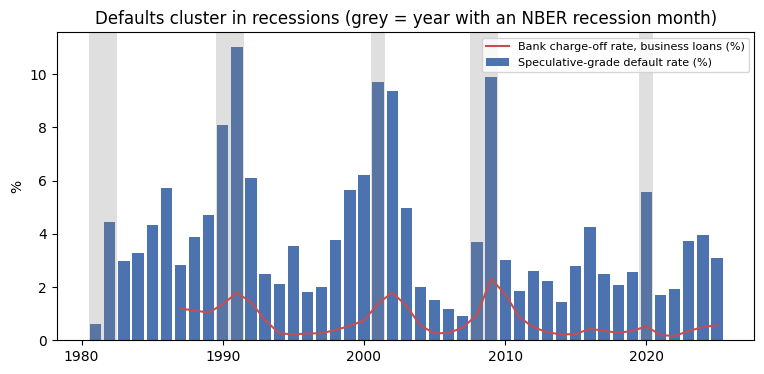

In [16]:
sg = annual_raw["SG"]
recession_year = to_period(raw["USREC"], "YE")
recession_year.index = recession_year.index.year
recession_year = recession_year.loc[sg.index[0]:sg.index[-1]]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(sg.index, sg, color="#4C72B0", label="Speculative-grade default rate (%)")
for y in recession_year[recession_year > 0].index:
    ax.axvspan(y - 0.5, y + 0.5, color="grey", alpha=0.25, lw=0)
ax.plot(annual.index, annual["CORBLACBS"], color="#C44E52", lw=1.5, label="Bank charge-off rate, business loans (%)")
ax.set(title="Defaults cluster in recessions (grey = year with an NBER recession month)", xlabel="", ylabel="%")
ax.legend(fontsize=8, loc="upper right")
fig.savefig(ROOT / "reports" / "figures" / "default_rates_vs_recessions.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the result:** the four peaks — 1991, 2001–02, 2009 and 2020 — all fall in or just after a recession, and bank charge-offs on business loans rise at the same time. Between recessions the default rate stays low for years. That persistence is what the AR(1) cycle $Z_t = \phi Z_{t-1} + \sqrt{1-\phi^2} \eta_t$ in NB03 captures.

### 6.2 Which public series move with defaults?

$$\rho = \text{correlation of the annual speculative-grade default rate with each series, } 1987\text{–}2025$$

In [17]:
drivers = ["CORBLACBS", "DRBLACBS", "BAA10Y", "UNRATE", "NFCI", "GDP_growth", "USREC"]
corr = annual[drivers].corrwith(annual_raw.loc[1987:2025, "SG"]).sort_values(ascending=False)
corr.to_frame("correlation with SG default rate")

,correlation with SG default rate
CORBLACBS,0.775
USREC,0.676
DRBLACBS,0.576
NFCI,0.366
BAA10Y,0.364
UNRATE,0.193
GDP_growth,-0.498


**Reading the result:** defaults move most closely with bank charge-offs on business loans (0.78) and the recession flag (0.68), then loan delinquencies (0.58); they move against GDP growth (−0.50). The Baa spread is weaker (0.36): spreads price expected risk ahead of time rather than count defaults as they happen. Bank charge-offs are the public proxy NB03 uses to check the model's implied credit cycle.

## 7. Save interim and processed outputs

Interim = aligned but not model-ready; processed = what the engine reads. Both folders are git-ignored: S&P content cannot be redistributed, and every file is rebuilt by this notebook.

In [18]:
(DATA / "interim").mkdir(exist_ok=True)
(DATA / "processed").mkdir(exist_ok=True)

annual.to_parquet(DATA / "interim" / "fred_panel.parquet")
quarterly.to_parquet(DATA / "interim" / "fred_panel_quarterly.parquet")
M.to_parquet(DATA / "processed" / "transition_matrix_1y.parquet")
(annual_raw / 100).to_parquet(DATA / "processed" / "default_rates_annual.parquet")
factors.assign(factor=factors["factor_pct"] / 100).to_parquet(DATA / "processed" / "naic_factors.parquet")

sorted(p.name for p in [*(DATA / "interim").glob("*.parquet"), *(DATA / "processed").glob("*.parquet")])

['default_rates_annual.parquet',
 'fred_panel.parquet',
 'fred_panel_quarterly.parquet',
 'merton_dd_panel.parquet',
 'naic_factors.parquet',
 'transition_matrix_1y.parquet']

## Validation checks

- [x] **Matrix rows sum to 1** — after removing NR, every row of the 8 × 8 matrix sums to 1 within $10^{-9}$.
- [x] **Default column increases down the rating scale** — one-year PD rises from AAA to CCC/C, both in the matrix and in the average annual rates.
- [x] **No gaps in series after alignment** — no missing year (1987–2025) or quarter (1987 Q1–2026 Q2) in any series that exists from 1987.
- [x] **Factors match cited documents** — all 19 NAIC factors equal the Academy letter, and the portfolio adjustment is neutral (≈ 1) at the 824-issuer reference portfolio.

In [19]:
checks = {
    "Matrix rows sum to 1": bool(np.allclose(M.sum(axis=1), 1.0, atol=1e-9)),
    "Default column increases down the scale (matrix)": bool(M.loc[RATINGS, "D"].is_monotonic_increasing),
    "Default column increases down the scale (annual average)": bool(rates.mean().is_monotonic_increasing),
    "No gaps after alignment (core series)": bool(annual[core].notna().all().all() and quarterly[core].notna().all().all()),
    "Factors match the Academy letter": bool(check["match"].all()),
    "Portfolio adjustment neutral at 824 issuers": bool(abs(portfolio_adjustment(824) - 1) < 0.01),
}
pd.Series(checks).map({True: "PASS", False: "FAIL"})

Matrix rows sum to 1                                        PASS
Default column increases down the scale (matrix)            PASS
Default column increases down the scale (annual average)    PASS
No gaps after alignment (core series)                       PASS
Factors match the Academy letter                            PASS
Portfolio adjustment neutral at 824 issuers                 PASS
dtype: object

## Functions to move into the engine

| Function (this notebook) | Target module | Test |
|---|---|---|
| `load_fred`, `to_period` | `creditengine.data.fred` | no gaps after alignment (check 3) |
| `clean_matrix` (NR pro rata, absorbing D) | `creditengine.data.rating_agency` | rows sum to 1; default column increasing |
| Matrix powers vs cumulative table | `creditengine.models.migration` | year 1 equal by construction; gap reported (V-03) |
| `portfolio_adjustment` | `creditengine.data.naic` | ≈ 1 at 824 issuers |
| Factor-to-letter map (middle notch) | `creditengine.data.naic` | factors equal the Academy letter |
| Annual and quarterly FRED panels | `scripts/build_interim.py` | — |

## Findings and next steps

**Key results**
- **One-year PD by rating** (S&P 1981–2025, NR removed): AAA 0.00%, AA 0.02%, A 0.04%, BBB 0.14%, BB 0.61%, B 3.28%, CCC/C 30.8%.
- **Long horizon:** compounding the one-year matrix matches investment-grade cumulative defaults (BBB, 5 years: 1.23% vs 1.33%) but overstates speculative grade (B, 10 years: 39.5% vs 21.7%).
- **Credit cycle:** speculative-grade defaults peak in 1991, 2001–02, 2009 and 2020; every peak is in or just after a recession. Correlation with bank charge-offs 0.78, with GDP growth −0.50.
- **Capital:** all 19 NAIC factors match the Academy letter; factor rises from 0.29% (AAA) to 22.8% (CCC/C); portfolio adjustment 0.996 at 824 issuers.

**Assumptions** (record in `docs/assumption_register.md`)
- A-01 unchanged: S&P global matrix 1981–2025, NR removed pro rata, default absorbing.
- A-06 unchanged: Academy 2021 pre-tax factors; each letter uses its middle notch.
- Added: annual and quarterly values are period averages; a period is a recession if any month is.

**Limitations** (record in `docs/limitations.md`)
1. **Markov matrix vs history:** one fixed one-year matrix overstates long-horizon speculative-grade defaults and slightly understates AAA; it also ignores the credit cycle (handled in NB03).
2. **Global, issuer-weighted data:** the S&P history is global corporates; a US insurer's book is US-heavy and value-weighted.
3. **Letter, not notch:** BBB+ and BBB− share one PD and one capital factor (middle notch).
4. **NR treatment:** spreading withdrawn ratings pro rata assumes they would have behaved like the rest; if withdrawals hide weaker issuers, PDs are slightly understated.
5. **Short CRE history:** CRE delinquency and charge-offs start in 1991 and CRE prices in 2005 — only two downturns for calibrating NB07.

**Next:** NB04 (rating migration and thresholds), then NB07 (commercial mortgages).